# SOM

En este cuaderno se va a investigar si las señales del bosson de Higgs y las señales de fondo se agrupan entre ellas de forma natural o por el contrario se mezclan. 

Para esta parte de análisis se van a utilizar los conjuntos de entrenamiento, tanto el que tiene solo las variables PRI como el que tiene ambas (PRI y DER).

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [58]:
Entrenamiento = pd.read_csv("Entrenamiento.csv")

## Desarrollo

In [59]:
Entrenamiento_DER = Entrenamiento.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Entrenamiento_PRI = Entrenamiento_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)

print(f"{Entrenamiento_PRI.shape}")
print(f"{Entrenamiento_DER.shape}")

(250000, 17)
(250000, 30)


### Configuración y justificación de los hiperparámetros del SOM

Se han elegido 4 épocas, es decir, 1000000 iteraciones, porque son suficientes para que el mapa se organice y podamos sacar conclusiones.  

La heurística de Vesanto (5√N) daría unas 2500 neuronas, es decir, una rejilla de dimensión 50×50 neuronas, con unos 2500 eventos por neurona de media, lo que permite que varios eventos compartan neurona y se formen grupos. Sin embargo, se va a implementar una más pequeña de 20x20 para visualizar de forma más clara las agrupaciones que se han descrito al principio. Por eso, la matriz de pesos es de 20x20: 400 neuronas con 17 pesos cada una.  

Como función de vecindad usamos la gaussiana, porque la influencia de la BMU disminuye de forma suave con la distancia en la rejilla: las neuronas cercanas se actualizan más que las lejanas, lo que ayuda a que las neuronas vecinas acaben representando datos parecidos.  
El radio inicial será de σ₀ = 10, que es la mitad del lado, y bajará hasta 1. La tasa de aprendizaje baja de 0,1 a 0,01, unos valores de partida habituales. En ambos casos, calculamos $\tau$ para que lleguen a su valor final en la última iteración.  

In [60]:
# número de iteraciones 
EPOCAS = 4
MAX_ITERACIONES = EPOCAS * len(Entrenamiento_PRI)

rng = np.random.default_rng(42)

Entrenamiento_PRI_numpy = Entrenamiento_PRI.to_numpy()
Entrenamiento_DER_numpy = Entrenamiento_DER.to_numpy()

pesos_PRI = rng.random((400, 17)) # el vector de cada neurona
neuronas_PRI = np.indices((20,20)).reshape(2, -1).T # posición de cada neurona en la matriz final

pesos_DER = rng.random((400,30))
neuronas_DER = np.indices((20,20)).reshape(2, -1).T

# distancia euclídea
def distancia(posicion1, posicion2):
    return np.sqrt(np.sum((posicion1 - posicion2)**2, axis=-1))

# radio de vecindad
RADIO_INICIAL = 10 # queremos que baje a radio = 1
RADIO_FINAL = 1
TAU_RADIO = MAX_ITERACIONES / np.log(RADIO_INICIAL/RADIO_FINAL) # tau = T / (ln(RADIO_INICIAL / RADIO_FINAL))

def radio_vecindad(t):
    return RADIO_INICIAL * np.exp(-t / TAU_RADIO)

# función de vecindad
def vecindad(t, posicion_bmu, posicion_neurona):
    return np.exp(-(distancia(posicion_bmu, posicion_neurona))**2/ (2*radio_vecindad(t)**2))

# tasa de aprendizaje
TASA_INICIAL = 0.1 # queremos que baje a 0.01
TASA_FINAL = 0.01
TAU_TASA = MAX_ITERACIONES / np.log(TASA_INICIAL / TASA_FINAL)

def tasa_aprendizaje(t):
    return TASA_INICIAL * np.exp(-t/TAU_TASA)

### Entrenamiento

In [61]:
# función BMU: elige la neurona más parecida

def bmu(vector_entrada, vector_pesos):
    return np.argmin(distancia(vector_entrada, vector_pesos)) 

def adaptacion_pesos(vector_pesos, tasa_aprendizaje, f_vecindad, vector_entrada):
    return vector_pesos + tasa_aprendizaje * f_vecindad * (vector_entrada - vector_pesos)

t = 1
# Entrenamientos para el PRI
for i in range(EPOCAS):
    orden_PRI = rng.permutation(len(Entrenamiento_PRI_numpy))  # barajar en cada época
    for j in orden_PRI:
        x_PRI = Entrenamiento_PRI_numpy[j]
        c_PRI = bmu(x_PRI, pesos_PRI)
        t_aprendizaje = tasa_aprendizaje(t)


        f_vecindad_PRI = vecindad(t, neuronas_PRI[c_PRI], neuronas_PRI)   # 400 valores de golpe
        pesos_PRI = adaptacion_pesos(pesos_PRI, t_aprendizaje, f_vecindad_PRI[:, None], x_PRI)
        t = t + 1

t = 1
# Entrenamientos para el PRI + DER
for i in range(EPOCAS):
    orden_DER = rng.permutation(len(Entrenamiento_DER_numpy))  # barajar en cada época
    for j in orden_DER:
        x_DER = Entrenamiento_DER_numpy[j]
        c_DER = bmu(x_DER, pesos_DER)
        t_aprendizaje = tasa_aprendizaje(t)


        f_vecindad_DER = vecindad(t, neuronas_DER[c_DER], neuronas_DER)   # 400 valores de golpe
        pesos_DER = adaptacion_pesos(pesos_DER, t_aprendizaje, f_vecindad_DER[:, None], x_DER)
        t = t + 1

In [62]:
# BMU de cada evento usando la función bmu del entrenamiento
LADO = 20

bmu_eventos_PRI = np.array([bmu(x, pesos_PRI) for x in Entrenamiento_PRI_numpy])
bmu_eventos_DER = np.array([bmu(x, pesos_DER) for x in Entrenamiento_DER_numpy])

es_senal = (Entrenamiento["Label"] == "s").to_numpy()


# conteos SIN ponderar por neurona
hits_total_PRI = np.bincount(bmu_eventos_PRI, minlength=LADO * LADO).reshape(LADO, LADO)
hits_senal_PRI = np.bincount(bmu_eventos_PRI[es_senal], minlength=LADO * LADO).reshape(LADO, LADO)
hits_fondo_PRI = hits_total_PRI - hits_senal_PRI

hits_total_DER = np.bincount(bmu_eventos_DER, minlength=LADO * LADO).reshape(LADO, LADO)
hits_senal_DER = np.bincount(bmu_eventos_DER[es_senal], minlength=LADO * LADO).reshape(LADO, LADO)
hits_fondo_DER = hits_total_DER - hits_senal_DER

proporcion_global = es_senal.mean()

### Resultados, visualizaciones y análisis

Una vez entrenado el SOM se va a visualizar si estos dos tipos se diferencian de forma natural o no. Para ello 

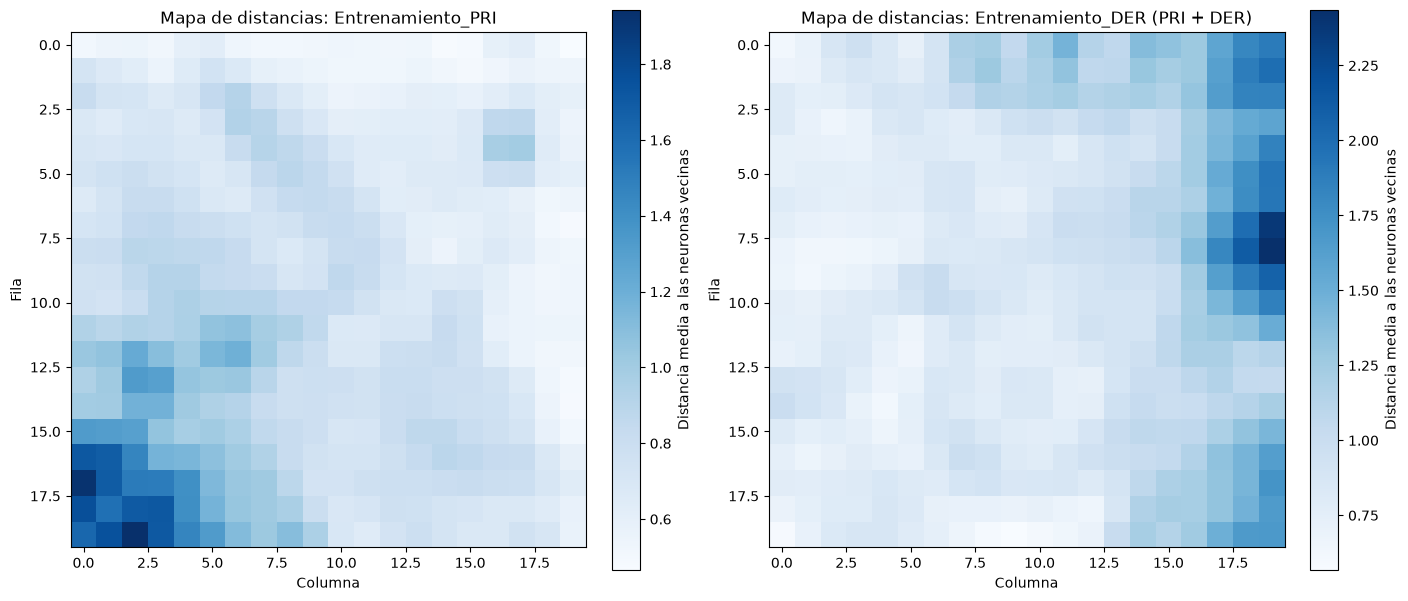

In [63]:
# mapa de distancias (U-matrix) de cada SOM
LADO = 20

def mapa_distancias(pesos, neuronas):
    distancias_mapa = np.zeros((LADO, LADO))
    for k in range(len(pesos)):
        vecinas = distancia(neuronas[k], neuronas) == 1
        fila, columna = neuronas[k]
        distancias_mapa[fila, columna] = distancia(pesos[k], pesos[vecinas]).mean()
    return distancias_mapa

distancias_mapa_PRI = mapa_distancias(pesos_PRI, neuronas_PRI)
distancias_mapa_DER = mapa_distancias(pesos_DER, neuronas_DER)

# cada mapa con su propia escala: el SOM_DER tiene 30 dimensiones y el SOM_PRI 17, sus distancias no son comparables en valor absoluto
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, datos, titulo in zip(axes,
                             [distancias_mapa_PRI, distancias_mapa_DER],
                             ["Entrenamiento_PRI", "Entrenamiento_DER (PRI + DER)"]):
    imagen = ax.imshow(datos, cmap="Blues")
    fig.colorbar(imagen, ax=ax, label="Distancia media a las neuronas vecinas")
    ax.set_title(f"Mapa de distancias: {titulo}")
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
plt.show()
# las zonas claras son neuronas parecidas entre sí, es decir, posibles grupos. Las oscuras marcan fronteras entre grupos.

#### Mapa de proporción de señal por neurona

Cada celda indica qué fracción de los eventos asignados a esa neurona son señal. En el conjunto de entrenamiento hay alrededor de un 34 % de señal sin ponderar, así que el mapa divergente está centrado en esa proporción global y no en el 50 %. En rojo están las neuronas con más señal que la media y en azul las que tienen menos. Se usan conteos sin ponderar porque los pesos de señal y de fondo son de órdenes de magnitud muy distintos y borrarían la estructura del mapa; los pesos se dejan para el AMS. Sobre el mapa se dibujan las fronteras de la U-matrix: si las zonas rojas quedan dentro de los grupos que delimitan, hay separación natural.

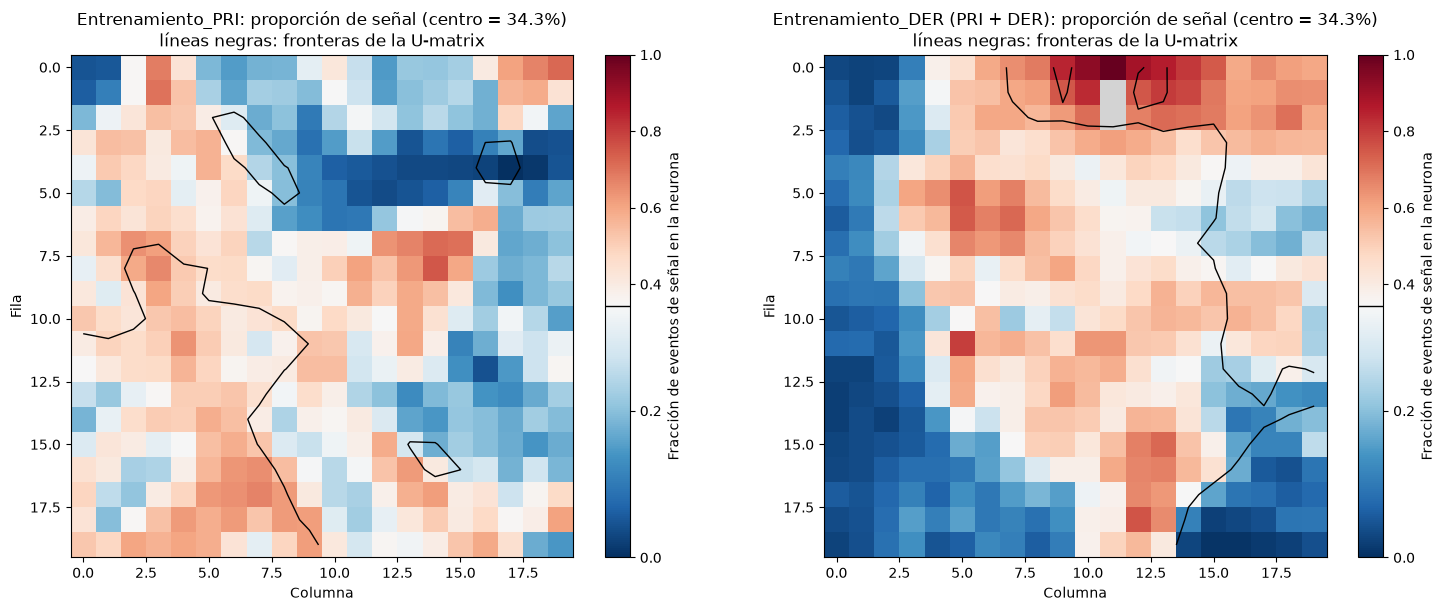

In [64]:
from matplotlib.colors import TwoSlopeNorm

# fracción de señal por neurona (conteos SIN ponderar); neuronas vacías en gris
def proporcion_por_neurona(hits_senal, hits_total):
    with np.errstate(divide="ignore", invalid="ignore"):
        proporcion = hits_senal / hits_total
    return np.ma.masked_where(hits_total == 0, proporcion)

proporcion_senal_PRI = proporcion_por_neurona(hits_senal_PRI, hits_total_PRI)
proporcion_senal_DER = proporcion_por_neurona(hits_senal_DER, hits_total_DER)

# mapa divergente centrado en la proporción global (~34 %), no en el 50 %; misma escala en los dos mapas para poder compararlos
norma = TwoSlopeNorm(vmin=min(proporcion_senal_PRI.min(), proporcion_senal_DER.min(), proporcion_global - 0.01),
                     vcenter=proporcion_global,
                     vmax=max(proporcion_senal_PRI.max(), proporcion_senal_DER.max(), proporcion_global + 0.01))
cmap_divergente = plt.get_cmap("RdBu_r").copy()
cmap_divergente.set_bad("lightgrey")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, proporcion, distancias_mapa, titulo in zip(axes,
                                                   [proporcion_senal_PRI, proporcion_senal_DER],
                                                   [distancias_mapa_PRI, distancias_mapa_DER],
                                                   ["Entrenamiento_PRI", "Entrenamiento_DER (PRI + DER)"]):
    imagen = ax.imshow(proporcion, cmap=cmap_divergente, norm=norma)
    barra = fig.colorbar(imagen, ax=ax, label="Fracción de eventos de señal en la neurona")
    barra.ax.axhline(proporcion_global, color="black", linewidth=1)

    # fronteras de la U-matrix de ese SOM (el 25 % de neuronas con más distancia) para ver si coinciden con las zonas de señal
    ax.contour(distancias_mapa, levels=[np.percentile(distancias_mapa, 75)], colors="black", linewidths=1)

    ax.set_title(f"{titulo}: proporción de señal (centro = {proporcion_global:.1%})\nlíneas negras: fronteras de la U-matrix")
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
plt.show()

Claramente las zonas no quedan delimitadas agrupadas dentro de la frontera de la U-matrix, por lo tanto, al menos respecto del csv de Entrenamiento_PRI no se diferencian de forma natural.

#### Hit maps de señal y de fondo

Cada mapa se normaliza por su propia clase: una celda indica qué porcentaje de todos los eventos de señal (o de fondo) cae en esa neurona. Así el fondo, que tiene casi el doble de eventos, no tapa a la señal. Los dos mapas usan la misma escala de color. Si las dos manchas ocupan regiones distintas del mapa, la separación se ve a simple vista; si se superponen, las clases están mezcladas.

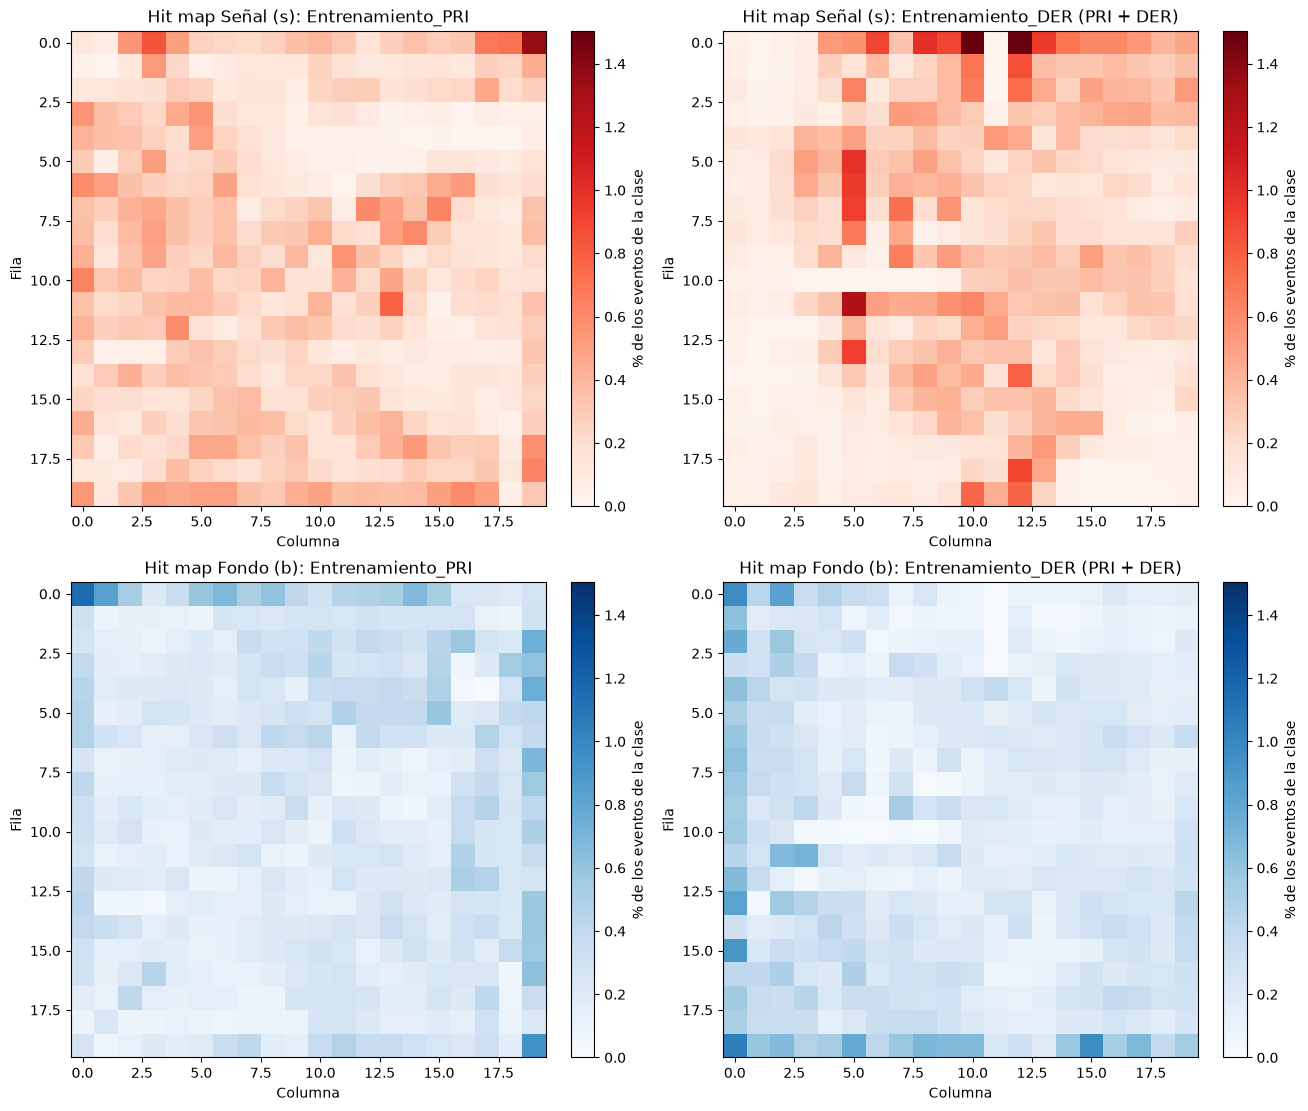

In [65]:
# hit maps normalizados por clase: % de los eventos de cada clase que caen en cada neurona
porcentaje_senal_PRI = 100 * hits_senal_PRI / hits_senal_PRI.sum()
porcentaje_fondo_PRI = 100 * hits_fondo_PRI / hits_fondo_PRI.sum()
porcentaje_senal_DER = 100 * hits_senal_DER / hits_senal_DER.sum()
porcentaje_fondo_DER = 100 * hits_fondo_DER / hits_fondo_DER.sum()

# misma escala en los cuatro mapas para poder comparar
escala_max = max(porcentaje_senal_PRI.max(), porcentaje_fondo_PRI.max(),
                 porcentaje_senal_DER.max(), porcentaje_fondo_DER.max())

# filas: señal / fondo; columnas: Entrenamiento_PRI / Entrenamiento_DER
fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
datos_mapas = [[porcentaje_senal_PRI, porcentaje_senal_DER],
               [porcentaje_fondo_PRI, porcentaje_fondo_DER]]
clases = [("Señal (s)", "Reds"), ("Fondo (b)", "Blues")]
conjuntos = ["Entrenamiento_PRI", "Entrenamiento_DER (PRI + DER)"]

for fila, (clase, cmap) in enumerate(clases):
    for columna, conjunto in enumerate(conjuntos):
        ax = axes[fila, columna]
        imagen = ax.imshow(datos_mapas[fila][columna], cmap=cmap, vmin=0, vmax=escala_max)
        fig.colorbar(imagen, ax=ax, label="% de los eventos de la clase")
        ax.set_title(f"Hit map {clase}: {conjunto}")
        ax.set_xlabel("Columna")
        ax.set_ylabel("Fila")
plt.show()

Ambas se reparten casi de forma homogénea por el mapa, sin agruparse de forma concreta (alta intensidad de color) en zonas distintas. Esto se corresponde al anterior gráfico, mostrando que no se agrupan de forma natural.

#### Planos de componentes

Hay un mapa por variable, y cada celda muestra el valor que tiene esa variable en el vector de pesos de la neurona. Si una variable tiene valores altos (o bajos) justo en la zona donde se concentra la señal, esa variable es una de las que provocan la separación. Las variables cuyo plano no tiene relación con el mapa de proporción de señal casi no ayudan a distinguir las dos clases.

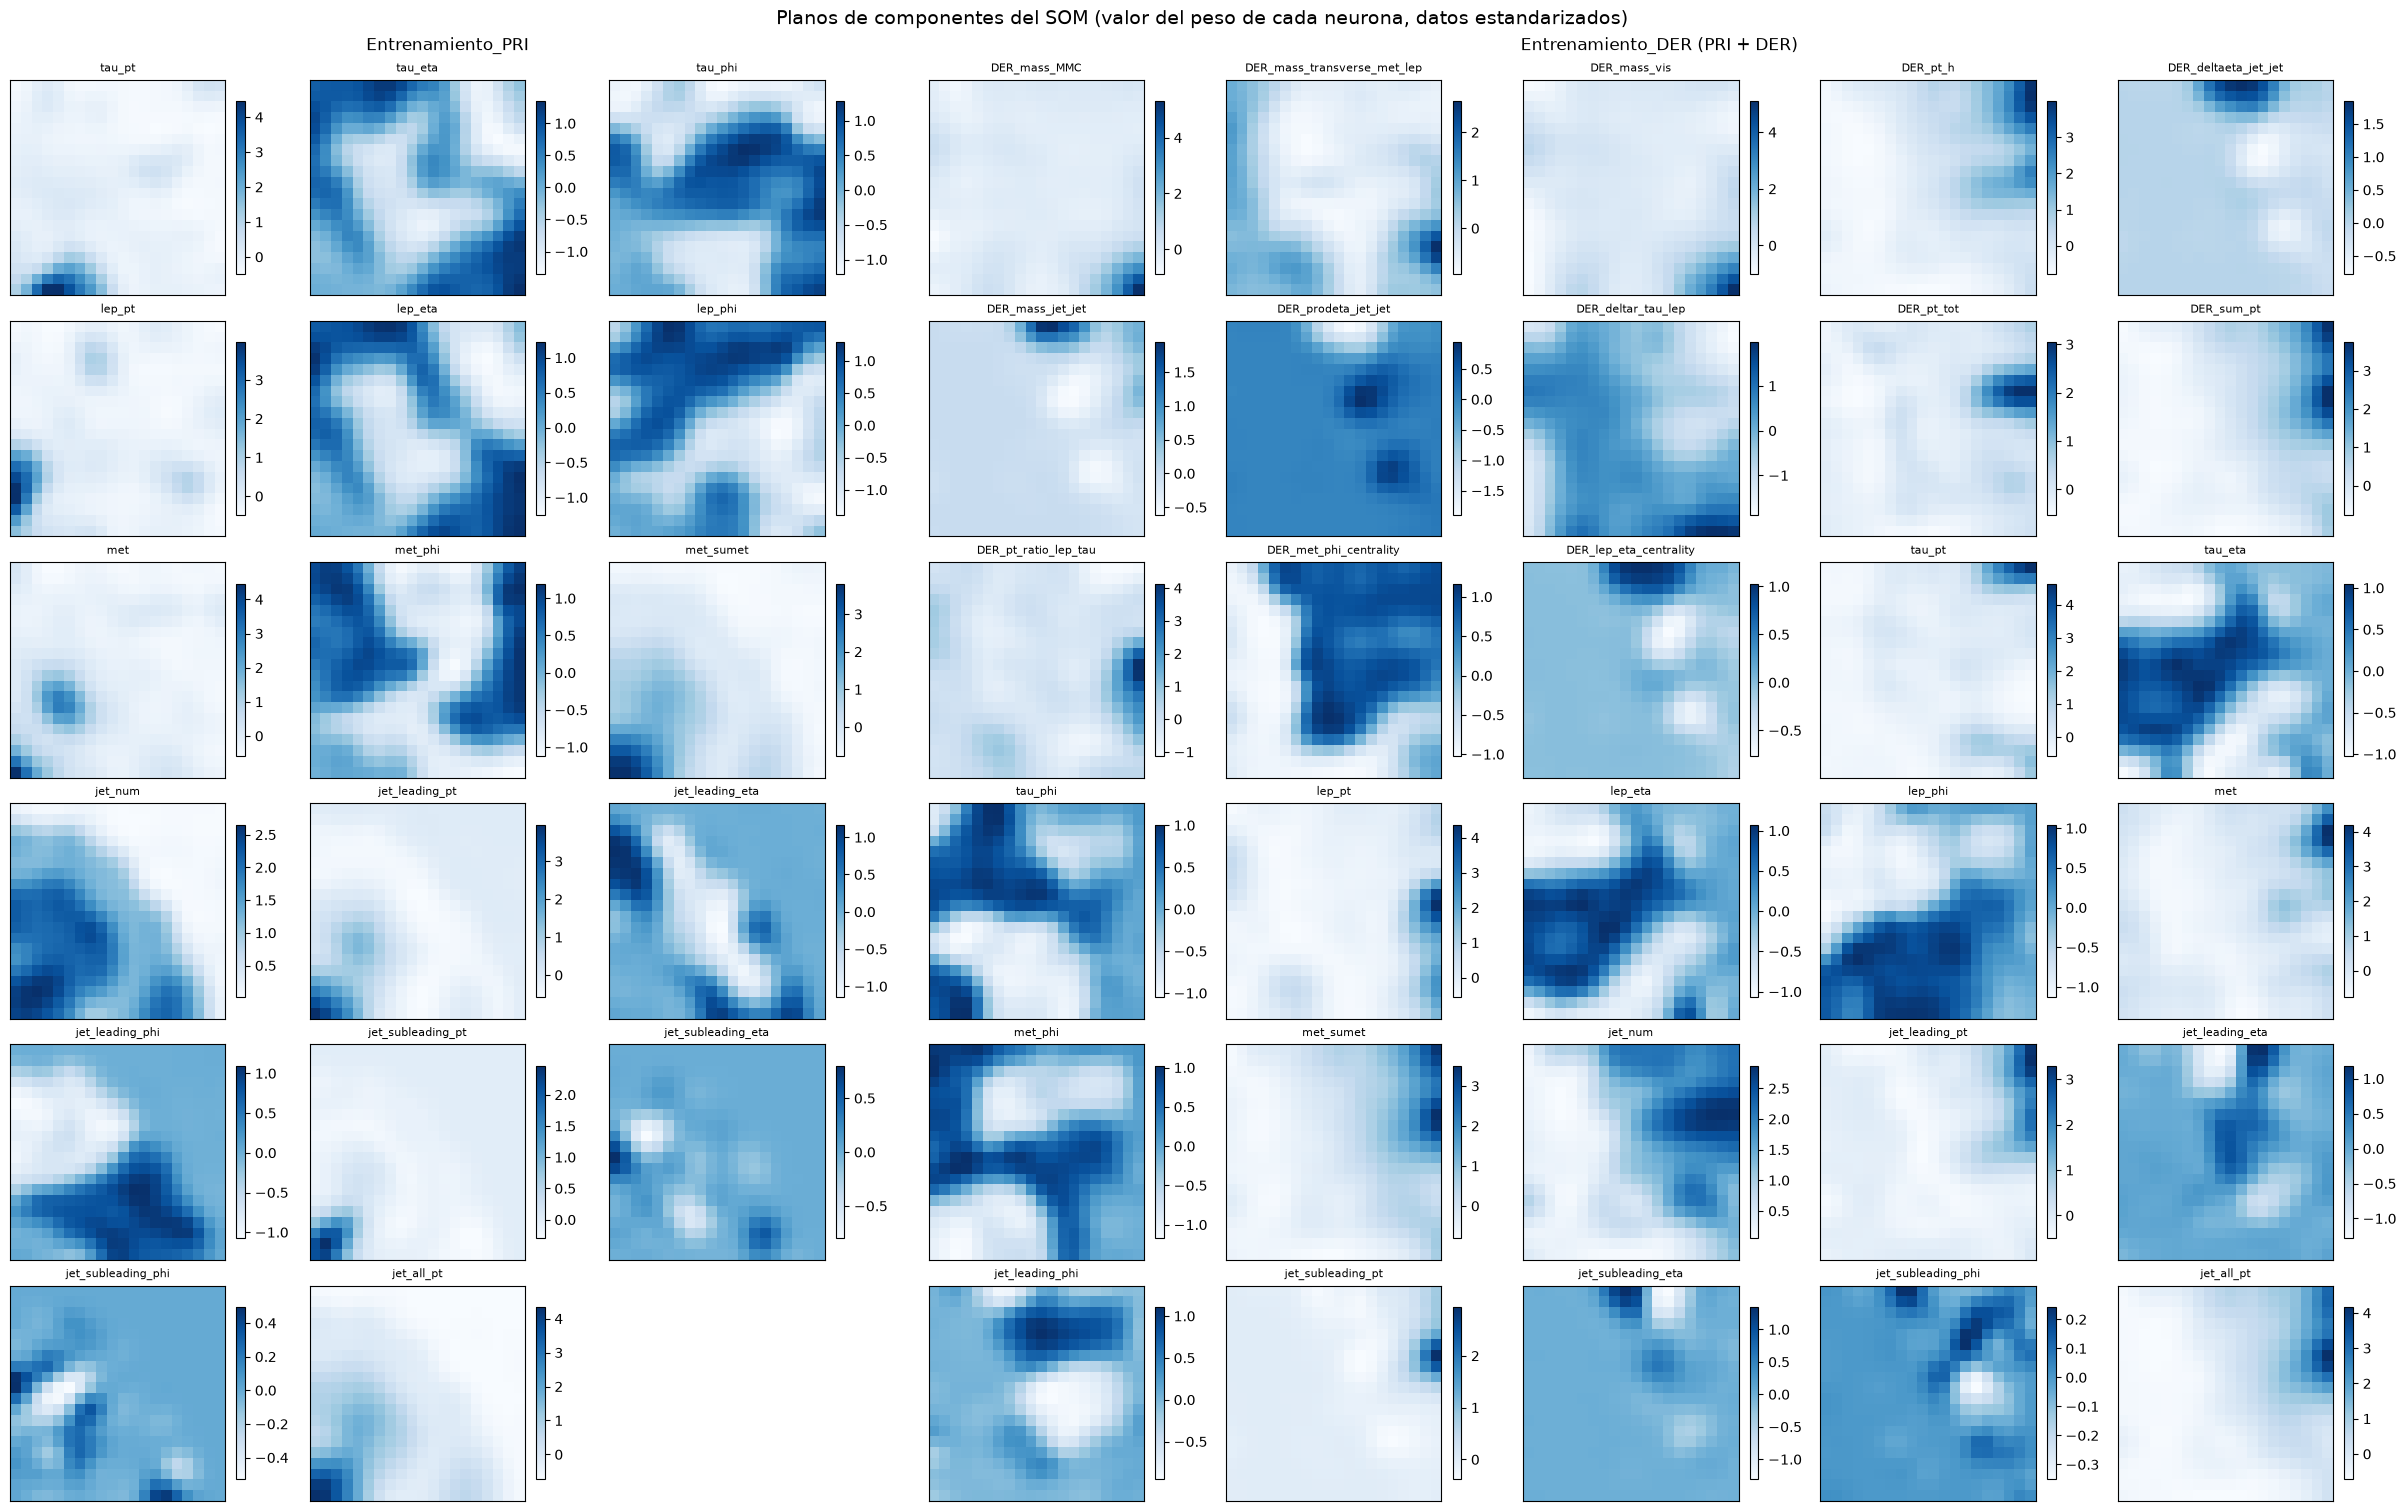

In [66]:
# planos de componentes: un mapa por variable con el peso que cada neurona tiene en ella
def dibujar_planos(subfig, pesos, nombres_variables, n_columnas, titulo):
    planos = pesos.reshape(LADO, LADO, len(nombres_variables))
    n_filas = int(np.ceil(len(nombres_variables) / n_columnas))
    axes = subfig.subplots(n_filas, n_columnas).ravel()

    for i, nombre in enumerate(nombres_variables):
        imagen = axes[i].imshow(planos[:, :, i], cmap="Blues")
        axes[i].set_title(nombre.replace("PRI_", ""), fontsize=8)  # las DER conservan el prefijo para distinguirlas
        axes[i].set_xticks([])
        axes[i].set_yticks([])
        subfig.colorbar(imagen, ax=axes[i], shrink=0.8)  # cada variable con su propia escala

    for ax in axes[len(nombres_variables):]:
        ax.axis("off")

    subfig.suptitle(titulo)

# 17 variables en 3 columnas y 30 en 5 columnas: los dos bloques quedan con 6 filas y se pueden ver uno al lado del otro
fig = plt.figure(figsize=(24, 15), constrained_layout=True)
subfig_PRI, subfig_DER = fig.subfigures(1, 2, width_ratios=[3, 5])
dibujar_planos(subfig_PRI, pesos_PRI, Entrenamiento_PRI.columns, 3, "Entrenamiento_PRI")
dibujar_planos(subfig_DER, pesos_DER, Entrenamiento_DER.columns, 5, "Entrenamiento_DER (PRI + DER)")

fig.suptitle("Planos de componentes del SOM (valor del peso de cada neurona, datos estandarizados)", fontsize=14)
plt.show()